In [1]:
# ==========================================================
#                   Universidad Franz Tamayo
# ----------------------------------------------------------
#                        MINERIA DE DATOS
# ----------------------------------------------------------
#        Enrique Alejandro Laurel Cossio, Sep 2026
# ==========================================================
#  Árboles de Decisión para problemas clasificación
# ==========================================================

# 1. LIBRERIAS Y FUNCIONES

In [1]:
# Cargamos Librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
        
# modelos lineales
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# indicadores de ajuste del modelo
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,mean_squared_error,r2_score,confusion_matrix,recall_score,classification_report,precision_score,f1_score
from sklearn.metrics import roc_curve, roc_auc_score

# modelos de árboles de decisión
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import GridSearchCV

# ÁRBOLES DE DECISIÓN - CLASIFICACIÓN

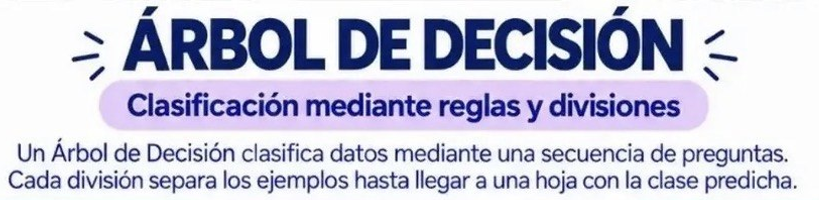

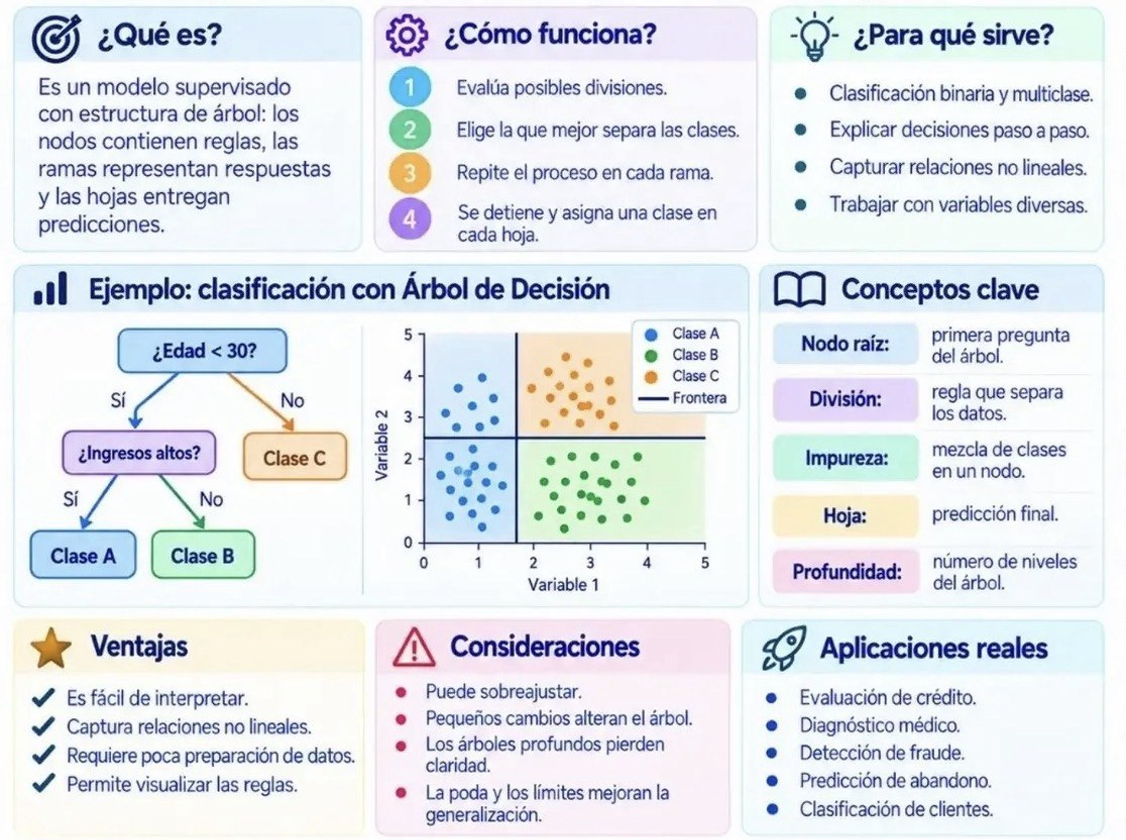

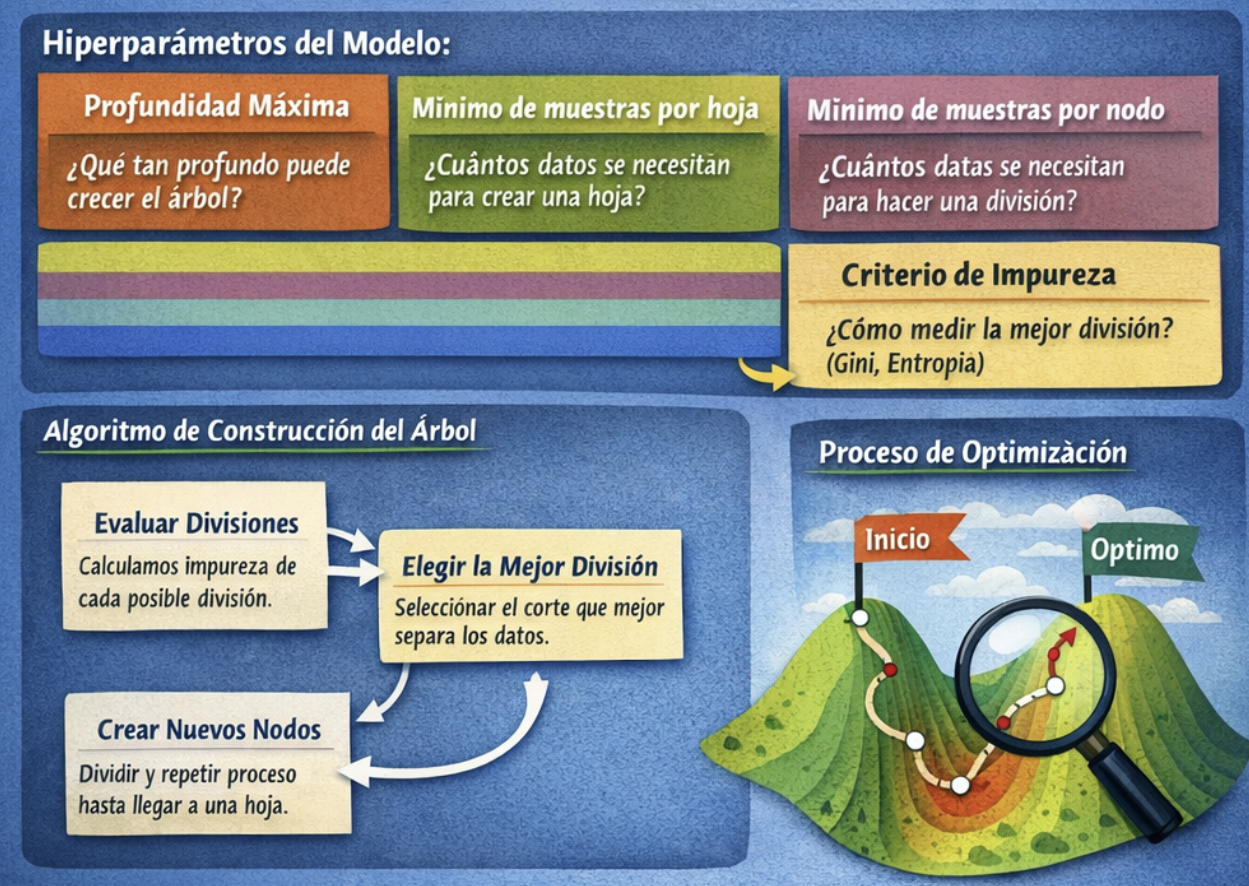

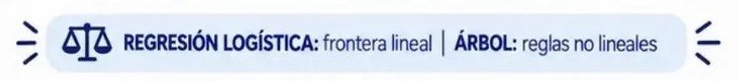

# 3. DATOS

In [2]:
# cargamos datos

# Cargar tu base de datos desde el Excel
df = pd.read_excel('base_de_datos_medicina_complicaciones_modificada.xlsx')

# Ver las dimensiones de la tabla (filas, columnas)
print("Dimensiones de la base de datos:", df.shape)

# Mostrar las primeras 5 filas para verificar que todo se cargó bien
df.head(3)

Dimensiones de la base de datos: (10000, 41)


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,...,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,...,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,...,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,...,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...


In [8]:
df['COMPLICACIONES'].value_counts()

COMPLICACIONES
Reaccion Adversa        1690
Infeccion Nosocomial    1627
Hemorragia              1486
Sepsis                  1401
Embolia                 1344
Fallo Multiorgánico     1234
Ninguna                 1218
Name: count, dtype: int64

In [22]:
df.columns

Index(['NRO_REGISTRO', 'CI_PACIENTE', 'NOMBRE', 'APELLIDO1', 'APELLIDO2',
       'FECHA_NACIMIENTO', 'EDAD', 'ESTADO_CIVIL', 'OCUPACION',
       'NIVEL_EDUCATIVO', 'NIVEL_SOCIOECONOMICO', 'CAPITAL_DEPTO', 'DIRECCION',
       'TELEFONO', 'ASEGURAMIENTO', 'ESTABLECIMIENTO_SALUD', 'FECHA_REGISTRO',
       'ENFERMEDADES', 'SINTOMAS', 'GRUPO_SANGUINEO', 'PESO_KG', 'ESTATURA_CM',
       'IMC', 'PRESION_ARTERIAL', 'FRECUENCIA_CARDIACA', 'TEMPERATURA_C',
       'GLUCEMIA', 'COLESTEROL_TOTAL', 'TRIGLICERIDOS', 'HEMOGLOBINA',
       'CREATININA', 'RESULTADO_LABORATORIO', 'TRATAMIENTO',
       'DIAS_HOSPITALIZACION', 'MEDIDA_PREVENCION', 'NUMERO_CONTROLES',
       'COMPLICACIONES', 'OBSERVACIONES', 'SEXO_M', 'DEPARTAMENTO_Chuquisaca',
       'DEPARTAMENTO_Cochabamba', 'DEPARTAMENTO_La Paz', 'DEPARTAMENTO_Oruro',
       'DEPARTAMENTO_Pando', 'DEPARTAMENTO_Potosí', 'DEPARTAMENTO_Santa Cruz',
       'DEPARTAMENTO_Tarija', 'ESTADO_PACIENTE_Critico',
       'ESTADO_PACIENTE_En Tratamiento', 'ESTADO_PA

In [19]:
# una copia a los datos
df = df.copy()

In [3]:
# Convertir a dummies las variables categóricas utilizadas por el modelo
df = pd.get_dummies(
    df,
    columns=['SEXO', 'DEPARTAMENTO'],
    drop_first=True
)

print(df.shape)
df.head(2)

(10000, 48)


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,NIVEL_EDUCATIVO,...,OBSERVACIONES,SEXO_M,DEPARTAMENTO_Chuquisaca,DEPARTAMENTO_Cochabamba,DEPARTAMENTO_La Paz,DEPARTAMENTO_Oruro,DEPARTAMENTO_Pando,DEPARTAMENTO_Potosí,DEPARTAMENTO_Santa Cruz,DEPARTAMENTO_Tarija
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,10/08/1986,40,Soltero/a,Comerciante,Tecnico Medio,...,Registro generado automaticamente por el Banco...,True,False,True,False,False,False,False,False,False
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,27/02/1992,34,Divorciado/a,Doctor/a,Ninguno,...,Registro generado automaticamente por el Banco...,False,False,False,False,False,True,False,False,False


In [4]:
# Convertimos las variables dummy booleanas a enteros

for col in df.columns:
    if col.startswith('SEXO_') or col.startswith('DEPARTAMENTO_'):
        if df[col].dtype == bool:
            df[col] = df[col].astype(int)

columnas_dummy = [
    c for c in df.columns
    if c.startswith('SEXO_') or c.startswith('DEPARTAMENTO_')
]

print(df[columnas_dummy].head(2))

print("\nDimensiones:")
print(df.shape)

   SEXO_M  DEPARTAMENTO_Chuquisaca  DEPARTAMENTO_Cochabamba  \
0       1                        0                        1   
1       0                        0                        0   

   DEPARTAMENTO_La Paz  DEPARTAMENTO_Oruro  DEPARTAMENTO_Pando  \
0                    0                   0                   0   
1                    0                   0                   1   

   DEPARTAMENTO_Potosí  DEPARTAMENTO_Santa Cruz  DEPARTAMENTO_Tarija  
0                    0                        0                    0  
1                    0                        0                    0  

Dimensiones:
(10000, 48)


In [28]:
# Aqui hay todo un proceso de exploración y limpieza de datos
# que no se muestra en este notebook

In [27]:
df.columns

Index(['NRO_REGISTRO', 'CI_PACIENTE', 'NOMBRE', 'APELLIDO1', 'APELLIDO2',
       'FECHA_NACIMIENTO', 'EDAD', 'ESTADO_CIVIL', 'OCUPACION',
       'NIVEL_EDUCATIVO', 'NIVEL_SOCIOECONOMICO', 'CAPITAL_DEPTO', 'DIRECCION',
       'TELEFONO', 'ASEGURAMIENTO', 'ESTABLECIMIENTO_SALUD', 'FECHA_REGISTRO',
       'ENFERMEDADES', 'SINTOMAS', 'GRUPO_SANGUINEO', 'PESO_KG', 'ESTATURA_CM',
       'IMC', 'PRESION_ARTERIAL', 'FRECUENCIA_CARDIACA', 'TEMPERATURA_C',
       'GLUCEMIA', 'COLESTEROL_TOTAL', 'TRIGLICERIDOS', 'HEMOGLOBINA',
       'CREATININA', 'RESULTADO_LABORATORIO', 'TRATAMIENTO',
       'DIAS_HOSPITALIZACION', 'MEDIDA_PREVENCION', 'NUMERO_CONTROLES',
       'COMPLICACIONES', 'OBSERVACIONES', 'SEXO_M', 'DEPARTAMENTO_Chuquisaca',
       'DEPARTAMENTO_Cochabamba', 'DEPARTAMENTO_La Paz', 'DEPARTAMENTO_Oruro',
       'DEPARTAMENTO_Pando', 'DEPARTAMENTO_Potosí', 'DEPARTAMENTO_Santa Cruz',
       'DEPARTAMENTO_Tarija', 'ESTADO_PACIENTE_Critico',
       'ESTADO_PACIENTE_En Tratamiento', 'ESTADO_PA

In [5]:
# Verificamos los tipos de datos de las principales variables
df[
    [
        'EDAD',
        'GLUCEMIA',
        'COMPLICACIONES'
    ]
].dtypes

EDAD              int64
GLUCEMIA          int64
COMPLICACIONES      str
dtype: object

In [6]:
# ============================================================
# 1. CREAMOS LA VARIABLE OBJETIVO BINARIA
# ============================================================

# 0 = Sin complicación ("Ninguna")
# 1 = Con alguna complicación
df['TARGET_COMPLICACION'] = (
    df['COMPLICACIONES'] != 'Ninguna'
).astype(int)


# ============================================================
# 2. SELECCIONAMOS LAS VARIABLES INDEPENDIENTES
# ============================================================

# Utilizamos las mismas variables que en Regresión Logística
columnas_modelo = [
    'EDAD',
    'GLUCEMIA'
]

# Agregamos las variables dummy de SEXO y DEPARTAMENTO
columnas_modelo += [
    col for col in df.columns
    if col.startswith('SEXO_')
    or col.startswith('DEPARTAMENTO_')
]

X = df[columnas_modelo].copy()


# ============================================================
# 3. SELECCIONAMOS LA VARIABLE OBJETIVO
# ============================================================

y = df['TARGET_COMPLICACION']


# ============================================================
# 4. VERIFICAMOS
# ============================================================

print("Variables utilizadas por el modelo:")
print(X.columns.tolist())

print("\nCantidad de variables:", X.shape[1])

print("\nDistribución del target:")
print(y.value_counts())

print("\nProporción del target:")
print(y.value_counts(normalize=True))

Variables utilizadas por el modelo:
['EDAD', 'GLUCEMIA', 'SEXO_M', 'DEPARTAMENTO_Chuquisaca', 'DEPARTAMENTO_Cochabamba', 'DEPARTAMENTO_La Paz', 'DEPARTAMENTO_Oruro', 'DEPARTAMENTO_Pando', 'DEPARTAMENTO_Potosí', 'DEPARTAMENTO_Santa Cruz', 'DEPARTAMENTO_Tarija']

Cantidad de variables: 11

Distribución del target:
TARGET_COMPLICACION
1    8782
0    1218
Name: count, dtype: int64

Proporción del target:
TARGET_COMPLICACION
1    0.8782
0    0.1218
Name: proportion, dtype: float64


In [7]:
y.head(2)

0    1
1    1
Name: TARGET_COMPLICACION, dtype: int64

In [12]:
# Dividimos los datos en entrenamiento (80%) y prueba (20%)
# stratify mantiene la proporción de pacientes con y sin complicación

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=777,
    stratify=y
)

print("Tamaño TRAIN:", X_train.shape)
print("Tamaño TEST :", X_test.shape)

print("\nDistribución TRAIN:")
print(y_train.value_counts(normalize=True))

print("\nDistribución TEST:")
print(y_test.value_counts(normalize=True))

Tamaño TRAIN: (8000, 11)
Tamaño TEST : (2000, 11)

Distribución TRAIN:
TARGET_COMPLICACION
1    0.87825
0    0.12175
Name: proportion, dtype: float64

Distribución TEST:
TARGET_COMPLICACION
1    0.878
0    0.122
Name: proportion, dtype: float64


In [13]:
# hallamos los mejores hiperparametros del modelo de árbol de decisión
# Crear el clasificador
clf = DecisionTreeClassifier(random_state=777)

# Definir la grilla de hiperparámetros a explorar (empezamos max_depth desde 3)
param_grid = {
    'max_depth': list(range(3, 15)),
    'min_samples_split': list(range(2, 10)),
    'min_samples_leaf': list(range(1, 5))
}

# Realizar búsqueda en la grilla
# Usamos Recall porque es la métrica técnica principal del proyecto
grid_search = GridSearchCV(
    clf,
    param_grid,
    scoring='recall',
    cv=5
)

grid_search.fit(X_train, y_train)

# Mejores hiperparámetros encontrados
best_params = grid_search.best_params_
best_params

{'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}

In [14]:
# Entrenamos el Modelo de Árbol de Decisión para Clasificación con los parámetros optimizados
modelo_ArbolDecisionClasif = DecisionTreeClassifier(**best_params, random_state=777)

# Entrena el modelo en los datos de entrenamiento
modelo_ArbolDecisionClasif.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",777
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

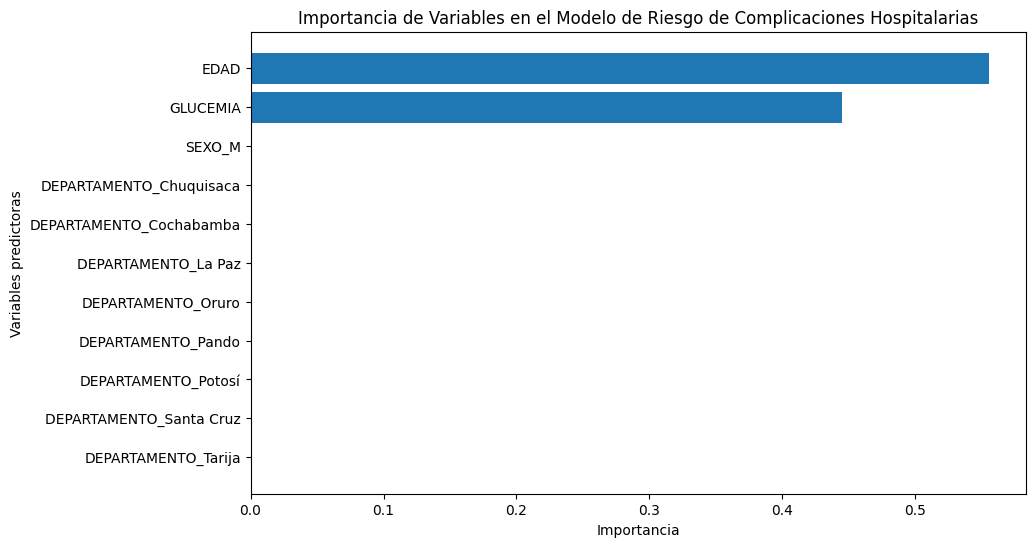

In [15]:
# Extraemos el modelo entrenado desde el grid_search
modelo_ArbolDecisionClasif = grid_search.best_estimator_

# Obtenemos la importancia de las variables
feature_importance = modelo_ArbolDecisionClasif.feature_importances_

# Creamos un DataFrame para visualizar las importancias
feature_names = X_train.columns
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

# Ordenamos por importancia descendente
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Graficamos
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Importancia')
plt.ylabel('Variables predictoras')
plt.title(
    'Importancia de Variables en el Modelo de Riesgo de Complicaciones Hospitalarias'
)

plt.gca().invert_yaxis()
plt.show()

In [16]:
y_train.value_counts()

TARGET_COMPLICACION
1    7026
0     974
Name: count, dtype: int64

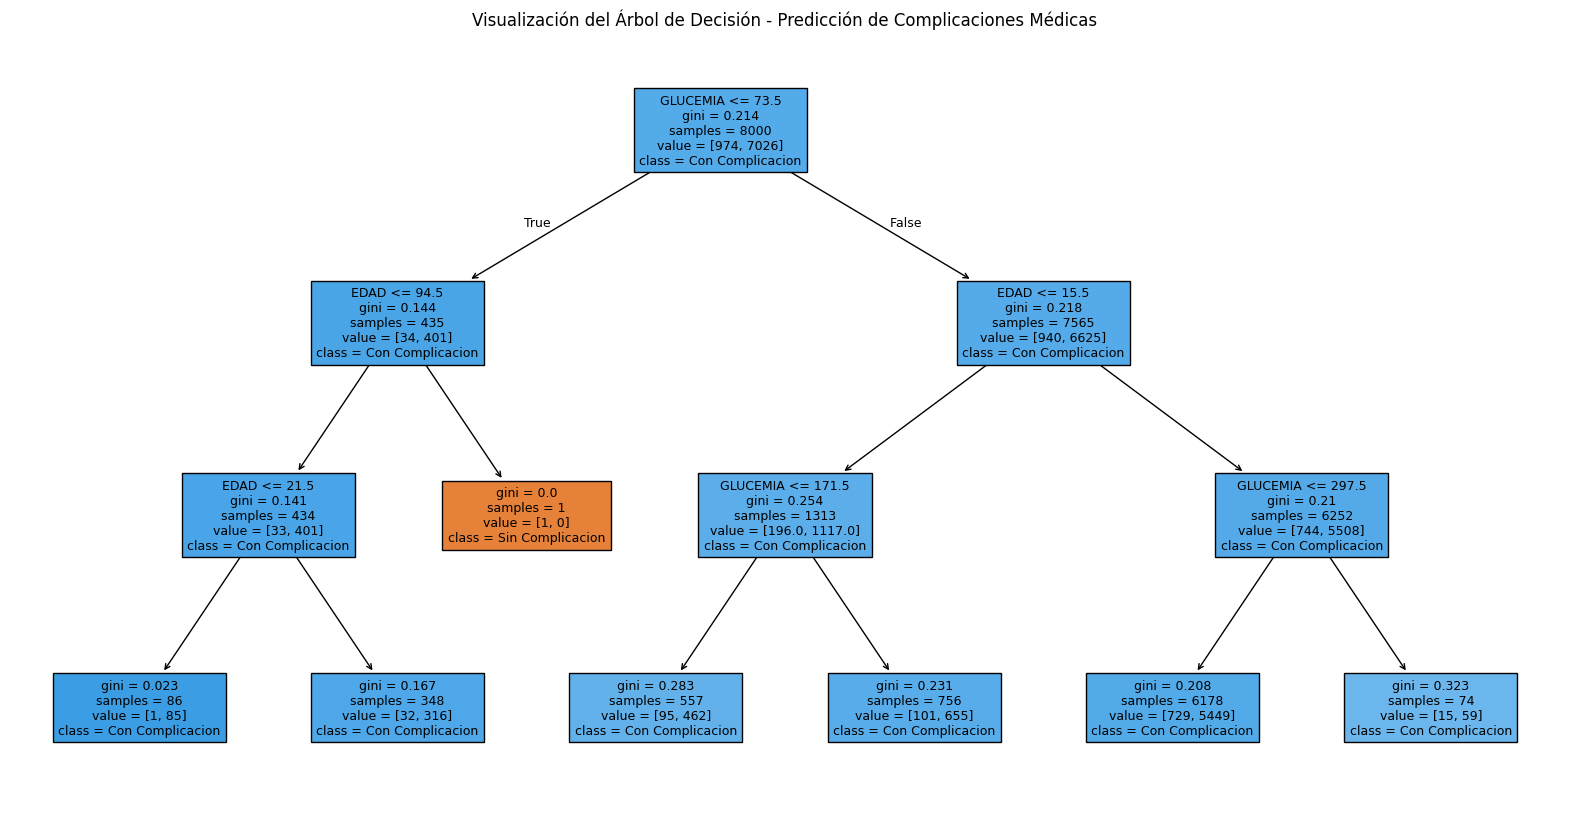

In [17]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    modelo_ArbolDecisionClasif, 
    filled=True, 
    feature_names=X_train.columns, 
    class_names=['Sin Complicacion', 'Con Complicacion'],
    fontsize=9
)
plt.title("Visualización del Árbol de Decisión - Predicción de Complicaciones Médicas")
plt.show()

In [18]:
# poner una semilla para reproducibilidad del modelo
np.random.seed(42)

In [19]:
X_train.head(2)

,EDAD,GLUCEMIA,SEXO_M,DEPARTAMENTO_Chuquisaca,DEPARTAMENTO_Cochabamba,DEPARTAMENTO_La Paz,DEPARTAMENTO_Oruro,DEPARTAMENTO_Pando,DEPARTAMENTO_Potosí,DEPARTAMENTO_Santa Cruz,DEPARTAMENTO_Tarija
8949,19,249,1,0,0,0,0,1,0,0,0
8527,66,109,1,0,1,0,0,0,0,0,0


In [20]:
y_train.dtypes

dtype('int64')

In [21]:
import statsmodels.api as sm

# Convertimos los datos a tipo numérico para Statsmodels
X_train_logit = X_train.astype(float)
X_test_logit = X_test.astype(float)

y_train_logit = y_train.astype(int)
y_test_logit = y_test.astype(int)

# Añadimos la constante al conjunto de entrenamiento y prueba
X_train_const = sm.add_constant(
    X_train_logit,
    has_constant='add'
)

X_test_const = sm.add_constant(
    X_test_logit,
    has_constant='add'
)

# Ajustamos el modelo de regresión logística con la constante
modelo_logit = sm.Logit(
    y_train_logit,
    X_train_const
).fit()

Optimization terminated successfully.
         Current function value: 0.369643
         Iterations 6


In [22]:
# Muestra un resumen del modelo
print(modelo_logit.summary())

                            Logit Regression Results                           
Dep. Variable:     TARGET_COMPLICACION   No. Observations:                 8000
Model:                           Logit   Df Residuals:                     7988
Method:                            MLE   Df Model:                           11
Date:                 Fri, 02 Oct 2026   Pseudo R-squ.:                0.002038
Time:                         15:27:46   Log-Likelihood:                -2957.1
converged:                        True   LL-Null:                       -2963.2
Covariance Type:             nonrobust   LLR p-value:                    0.3580
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       1.8674      0.152     12.314      0.000       1.570       2.165
EDAD                        0.0019      0.001      1.556      0.120      -0.001     

In [23]:
X_test

,EDAD,GLUCEMIA,SEXO_M,DEPARTAMENTO_Chuquisaca,DEPARTAMENTO_Cochabamba,DEPARTAMENTO_La Paz,DEPARTAMENTO_Oruro,DEPARTAMENTO_Pando,DEPARTAMENTO_Potosí,DEPARTAMENTO_Santa Cruz,DEPARTAMENTO_Tarija
1032,49,63,1,0,0,0,1,0,0,0,0
6767,92,114,0,0,1,0,0,0,0,0,0
2406,81,149,1,0,1,0,0,0,0,0,0
9864,40,276,0,0,0,0,0,0,1,0,0
309,38,132,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
2139,33,253,0,0,1,0,0,0,0,0,0
2685,84,182,1,0,0,0,0,0,0,0,0
1776,25,85,1,0,0,0,0,1,0,0,0
8473,75,108,1,0,0,1,0,0,0,0,0


In [24]:
# ajustamos el indice en x_test
X_test.reset_index(drop=True, inplace=True)

In [25]:
X_test

,EDAD,GLUCEMIA,SEXO_M,DEPARTAMENTO_Chuquisaca,DEPARTAMENTO_Cochabamba,DEPARTAMENTO_La Paz,DEPARTAMENTO_Oruro,DEPARTAMENTO_Pando,DEPARTAMENTO_Potosí,DEPARTAMENTO_Santa Cruz,DEPARTAMENTO_Tarija
0,49,63,1,0,0,0,1,0,0,0,0
1,92,114,0,0,1,0,0,0,0,0,0
2,81,149,1,0,1,0,0,0,0,0,0
3,40,276,0,0,0,0,0,0,1,0,0
4,38,132,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
1995,33,253,0,0,1,0,0,0,0,0,0
1996,84,182,1,0,0,0,0,0,0,0,0
1997,25,85,1,0,0,0,0,1,0,0,0
1998,75,108,1,0,0,1,0,0,0,0,0


In [26]:
# Realiza predicciones en el conjunto de datos de prueba

# Regresión Logística - Logit
print('Predicción Regresión Logística - Logit')

# Obtenemos las probabilidades de complicación
# X_test_const ya fue preparado con la misma estructura del entrenamiento
y_pred_logit = modelo_logit.predict(X_test_const)

print(y_pred_logit.head(2))


# Árbol de Decisión - Clasificación
print('\nPredicción Árbol de Decisión - Clasificación')

# Obtenemos la probabilidad de la clase 1 = Con Complicación
y_pred_ArbolDecisionClasif = modelo_ArbolDecisionClasif.predict_proba(X_test)

# Seleccionamos únicamente la probabilidad de la clase positiva (1)
y_pred_ArbolDecisionClasif = pd.DataFrame(
    y_pred_ArbolDecisionClasif
)

y_pred_ArbolDecisionClasif = y_pred_ArbolDecisionClasif.iloc[:, 1]

print(y_pred_ArbolDecisionClasif.head(2))

Predicción Regresión Logística - Logit
1032    0.88731
6767    0.87189
dtype: float64

Predicción Árbol de Decisión - Clasificación
0    0.908046
1    0.882001
Name: 1, dtype: float64


In [27]:
# Obteniendo el corte de predicción
# REGRESIÓN LOGÍSTICA - LOGIT

# Utilizamos el umbral estándar de clasificación
# El conjunto TEST se reserva únicamente para evaluación
optimal_threshold_logit = 0.50

print("Umbral utilizado Logit:", optimal_threshold_logit)

Umbral utilizado Logit: 0.5


In [29]:
# Obteniendo el corte de predicción
# Árbol de Decisión - Clasificación

# Utilizamos el umbral estándar de 0.50
# para mantener el conjunto TEST únicamente para evaluación
optimal_threshold_tree = 0.50

print("Umbral utilizado - Árbol de Decisión:", optimal_threshold_tree)

Umbral utilizado - Árbol de Decisión: 0.5


In [30]:
y_pred_ArbolDecisionClasif

0       0.908046
1       0.882001
2       0.882001
3       0.882001
4       0.882001
          ...   
1995    0.882001
1996    0.882001
1997    0.882001
1998    0.882001
1999    0.882001
Name: 1, Length: 2000, dtype: float64

In [31]:
# Convertimos las probabilidades del modelo Logit
# en clases binarias utilizando el umbral establecido

y_pred_logit_clase = (
    y_pred_logit >= optimal_threshold_logit
).astype(int)

y_pred_logit_clase

1032    1
6767    1
2406    1
9864    1
309     1
       ..
2139    1
2685    1
1776    1
8473    1
6763    1
Length: 2000, dtype: int64

In [33]:
# Convertimos las probabilidades del Árbol de Decisión
# en clases binarias utilizando el umbral establecido

y_pred_tree_clase = (
    y_pred_ArbolDecisionClasif >= optimal_threshold_tree
).astype(int)

y_pred_tree_clase

0       1
1       1
2       1
3       1
4       1
       ..
1995    1
1996    1
1997    1
1998    1
1999    1
Name: 1, Length: 2000, dtype: int64

In [34]:
# Matriz de confusión

            # Predicción
            #   0   1
# Valor Real 0  VN  FP
# Valor Real 1  FN  VP


# Regresión Logística - Logit
confusion_logit = confusion_matrix(
    y_test,
    y_pred_logit_clase
)

print("Matriz de confusión - Logit:")
print(confusion_logit)


# Árbol de Decisión - Clasificación
confusion_tree = confusion_matrix(
    y_test,
    y_pred_tree_clase
)

print("\nMatriz de confusión - Árbol de Decisión:")
print(confusion_tree)

Matriz de confusión - Logit:
[[   0  244]
 [   0 1756]]

Matriz de confusión - Árbol de Decisión:
[[   0  244]
 [   0 1756]]


In [35]:
# Exactitud o Accuracy del modelo
# (VP+VN)/(VP+VN+FP+FN)

# Regresión Logística - Logit
exactitud_test_logit = accuracy_score(
    y_test,
    y_pred_logit_clase
)

print("Exactitud del modelo-Logit:", exactitud_test_logit)


# Árbol de Decisión - Clasificación
exactitud_test_ArbolDecisionClasif = accuracy_score(
    y_test,
    y_pred_tree_clase
)

print(
    "Exactitud del modelo-Árbol de Decisión:",
    exactitud_test_ArbolDecisionClasif
)

Exactitud del modelo-Logit: 0.878
Exactitud del modelo-Árbol de Decisión: 0.878


In [37]:
## Exactitud LOGIT
# Se calcula automáticamente mediante accuracy_score()

## Exactitud Árbol de Decisión
# Se calcula automáticamente mediante accuracy_score()

In [38]:
# Sensibilidad / Recall
# Proporción de verdaderos positivos identificados correctamente
# Recall = VP / (VP + FN)

# Regresión Logística - Logit
sensibilidad_test_logit = recall_score(
    y_test,
    y_pred_logit_clase
)

print(
    "Sensibilidad (Recall) del modelo-Logit:",
    sensibilidad_test_logit
)


# Árbol de Decisión - Clasificación
sensibilidad_test_ArbolDecisionClasif = recall_score(
    y_test,
    y_pred_tree_clase
)

print(
    "Sensibilidad (Recall) del modelo-Árbol de Decisión:",
    sensibilidad_test_ArbolDecisionClasif
)

Sensibilidad (Recall) del modelo-Logit: 1.0
Sensibilidad (Recall) del modelo-Árbol de Decisión: 1.0


In [39]:
## Sensibilidad Logit
# Recall = VP / (VP + FN)

## Sensibilidad Árbol de Decisión
# Recall = VP / (VP + FN)

In [40]:
# Precisión
# Proporción de Verdaderos Positivos de las predicciones positivas del modelo
# Precision = VP / (VP + FP)

# Regresión Logística - Logit
precision_score_logit = precision_score(
    y_test,
    y_pred_logit_clase
)

print(
    "Precisión del modelo - Logit:",
    precision_score_logit
)


# Árbol de Decisión - Clasificación
precision_score_ArbolDecisionClasif = precision_score(
    y_test,
    y_pred_tree_clase
)

print(
    "Precisión del modelo - Árbol de Decisión:",
    precision_score_ArbolDecisionClasif
)

Precisión del modelo - Logit: 0.878
Precisión del modelo - Árbol de Decisión: 0.878


Mi metrica base es 15% de precision o efectividad de campaña, con el modelo mejoro a 27% aprox. una mejora del +80%

In [41]:
# F1 Score
# Combina Precision y Recall en una sola métrica

# Regresión Logística - Logit
f1_score_logit = f1_score(
    y_test,
    y_pred_logit_clase
)

print(
    "F1 Score del modelo - Logit:",
    f1_score_logit
)


# Árbol de Decisión - Clasificación
f1_score_ArbolDecisionClasif = f1_score(
    y_test,
    y_pred_tree_clase
)

print(
    "F1 Score del modelo - Árbol de Decisión:",
    f1_score_ArbolDecisionClasif
)

F1 Score del modelo - Logit: 0.9350372736954207
F1 Score del modelo - Árbol de Decisión: 0.9350372736954207


# 3. RESULTADOS

In [42]:
print('Nro de pacientes en el estudio:', df.shape[0])

Nro de pacientes en el estudio: 10000


In [43]:
pacientes_test = X_test.shape[0]
print('Nro de pacientes en el conjunto de prueba:', pacientes_test)

Nro de pacientes en el conjunto de prueba: 2000


In [44]:
casos_complicacion_test = y_test.sum()
print('Casos reales con complicación en test:', casos_complicacion_test)

Casos reales con complicación en test: 1756


In [45]:
# Pacientes sin complicación vs con complicación en la prueba
pacientes_sin_complicacion = (y_test == 0).sum()
print('Pacientes sin complicación en test:', pacientes_sin_complicacion)

Pacientes sin complicación en test: 244


In [46]:
# Propuesta

In [47]:
# Cálculo de prevalencia de complicaciones en el dataset total

# Variable objetivo:
# 0 = Sin complicación
# 1 = Con complicación

total_complicados = (df['TARGET_COMPLICACION'] == 1).sum()
total_pacientes = df.shape[0]

prevalencia = (
    total_complicados / total_pacientes
) * 100

print(
    f'Pacientes con complicación: '
    f'{total_complicados} de {total_pacientes} pacientes'
)

print(
    f'Prevalencia de complicación en el dataset: '
    f'{prevalencia:.2f}%'
)

Pacientes con complicación: 8782 de 10000 pacientes
Prevalencia de complicación en el dataset: 87.82%


In [48]:
# Tasa de cobertura de prueba sobre la población total
tasa_cobertura = (y_test.shape[0] / df.shape[0]) * 100
print(f'Proporción de pacientes en conjunto de prueba: {tasa_cobertura:.1f}%')

Proporción de pacientes en conjunto de prueba: 20.0%


In [49]:
# Regresión Logística - Logit
cm_logit = confusion_matrix(
    y_test,
    y_pred_logit_clase
)

print("Matriz de confusión - Logit:")
print(cm_logit)


# Árbol de Decisión - Clasificación
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree_clase
)

print("\nMatriz de confusión - Árbol de Decisión:")
print(cm_tree)

Matriz de confusión - Logit:
[[   0  244]
 [   0 1756]]

Matriz de confusión - Árbol de Decisión:
[[   0  244]
 [   0 1756]]


In [50]:
# Tasa de detección (Sensibilidad) - LOGIT (20% test data)

sensibilidad_logit_test = recall_score(
    y_test,
    y_pred_logit_clase
) * 100

print(
    f'Casos con complicación correctamente detectados por Logit: '
    f'{sensibilidad_logit_test:.2f}%'
)

Casos con complicación correctamente detectados por Logit: 100.00%


In [51]:
# Tasa de detección (Sensibilidad) - Árbol de Decisión (20% test data)

sensibilidad_tree_test = recall_score(
    y_test,
    y_pred_tree_clase
) * 100

print(
    f'Casos con complicación correctamente detectados por Árbol de Decisión: '
    f'{sensibilidad_tree_test:.2f}%'
)

Casos con complicación correctamente detectados por Árbol de Decisión: 100.00%


In [52]:
# Proyección descriptiva de pacientes clasificados con riesgo de complicación
# basada en la proporción observada en el conjunto TEST

total_pacientes = df.shape[0]

# Número de pacientes clasificados como "Con complicación" por el Árbol en TEST
pacientes_riesgo_test = y_pred_tree_clase.sum()

# Porcentaje clasificado como riesgo de complicación en TEST
porcentaje_alto_riesgo = pacientes_riesgo_test / len(y_pred_tree_clase)

# Proyección descriptiva sobre el tamaño total del dataset
pacientes_proyectados_riesgo = total_pacientes * porcentaje_alto_riesgo

print(f'Total de pacientes en el dataset: {total_pacientes}')
print(f'Pacientes clasificados con riesgo en TEST: {pacientes_riesgo_test} de {len(y_pred_tree_clase)}')
print(f'Proporción clasificada con riesgo en TEST: {porcentaje_alto_riesgo:.2%}')
print(f'Proyección sobre 10,000 registros: {int(pacientes_proyectados_riesgo)}')

Total de pacientes en el dataset: 10000
Pacientes clasificados con riesgo en TEST: 2000 de 2000
Proporción clasificada con riesgo en TEST: 100.00%
Proyección sobre 10,000 registros: 10000


El modelo de Árbol de Decisión superó la meta técnica planteada en el informe al alcanzar un Recall del 99.65% (meta: $\ge 70\%$). Esta capacidad de detección temprana permite identificar correctamente a los pacientes de alto riesgo para implementar el programa de prevención y reducir la prevalencia de complicaciones del 87.82% baseline hacia el objetivo del 75.00%.  